# Direction pilot: BottomUp / l1

Supervisor-requested pilot (see mentoring log): pick one relatively fast method/cost combination, optimize on `f1_all` (the old, direction-agnostic objective -- "for all transitions"), time it, and check whether `f1_warming` vs `f1_cooling` diverge on the resulting winning config.

**Why BottomUp/l1, not Pelt:** a quick timing check (5 series, mid-range pen) showed BottomUp/l1 at ~0.02s/series vs Binseg/l1 at ~1.3s/series vs Pelt/l1 at ~5.0s/series -- Pelt was unusably slow for a pilot at low-pen (heavily over-segmented) configs. BottomUp is 100x+ faster here and was competitive with Pelt in the earlier grid search (test_f1=0.854 vs Pelt's 0.857), so it's the right choice for a fast check.

**Expectation to test (per supervisor):** Melcher25 produces more symmetric synthetic DO events than the real ones, so little/no warming-vs-cooling gap is expected here -- if a gap shows up on NGRIP later, that would be an asymmetry NGRIP has and this synthetic data doesn't, not a bug in the method.

Edit `TRAIN_PATH`/`VAL_PATH` below to point at a different synthetic dataset (e.g. a version with more asymmetric transitions) without touching anything else in this notebook.

In [8]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from optuna.samplers import TPESampler

sys.path.insert(0, os.path.abspath("."))  # so `import optuna_search` finds this directory's module
import optuna_search as osr

# --- Edit these to point at different data / change the pilot's scope ---
TRAIN_PATH = osr.DEFAULT_TRAIN_PATH
VAL_PATH = osr.DEFAULT_VAL_PATH
METHOD, COST = "BottomUp", "l1"
N_TRIALS = 150
TIMEOUT_S = 300  # safety cap -- stop after this many seconds even if N_TRIALS isn't reached
OBJECTIVE = "all"  # matches the supervisor's request: optimize on f1_all, then inspect the warming/cooling split

# Early stopping -- same rule as optuna_search.py's --patience/--min-trials/--min-delta (see that
# module's docstring's 'Early stopping' section and `_make_early_stopping_callback`): the study
# stops once MIN_TRIALS have completed AND PATIENCE of them in a row pass with no improvement
# greater than MIN_DELTA over the running best. Scaled down from the full search's 150/75 to fit
# this pilot's much smaller N_TRIALS=150 budget -- MIN_TRIALS/PATIENCE keep the same 2:1 ratio.
MIN_TRIALS = 100
PATIENCE = 25
MIN_DELTA = 0.001

print(f"TRAIN_PATH={TRAIN_PATH}")
print(f"VAL_PATH={VAL_PATH}")
print(f"early stopping: min_trials={MIN_TRIALS}  patience={PATIENCE}  min_delta={MIN_DELTA}")

TRAIN_PATH=/Users/maryamniati/Documents/Syntheticdata/train_test_split_data/train.npz
VAL_PATH=/Users/maryamniati/Documents/Syntheticdata/train_test_split_data/validation.npz
early stopping: min_trials=100  patience=25  min_delta=0.001


In [9]:
# Restrict the joint (method, cost) search space to just METHOD/COST for this pilot --
# turns the search into 2 dimensions (pen, min_size), which is what makes this fast.
osr.METHODS = [METHOD]
osr.KEPT_COSTS = {METHOD: [COST]}
osr.PEN_BOUNDS = {METHOD: {COST: osr.PEN_BOUNDS[METHOD][COST]}}

search = osr.OptunaSearch(TRAIN_PATH, VAL_PATH, osr.TOLERANCE, n_jobs=-1, objective_metric=OBJECTIVE)
print(f"train seeds: {search.n_train}   validation seeds: {search.n_val}")

sampler = TPESampler(seed=42)
study = optuna.create_study(direction="maximize", sampler=sampler)

[I 2026-09-11 13:48:54,743] A new study created in memory with name: no-name-7eaae39e-fceb-408c-b83a-afe1d29cbb33


train seeds: 60   validation seeds: 20


In [10]:
stop_info = dict(stopped_early=False, stopped_at_trial=None, trials_since_improvement=None)
callbacks = [osr._make_early_stopping_callback(PATIENCE, MIN_TRIALS, MIN_DELTA, stop_info)]

t0 = time.perf_counter()
study.optimize(search.objective, n_trials=N_TRIALS, timeout=TIMEOUT_S, callbacks=callbacks, show_progress_bar=False)
wall = time.perf_counter() - t0

n_done = len(study.trials)
print(f"Ran {n_done} trial(s) in {wall:.1f}s  ({wall / max(n_done, 1):.3f}s/trial)")
if stop_info['stopped_early']:
    print(f"Stopped EARLY by the patience callback at trial #{stop_info['stopped_at_trial']} "
          f"({stop_info['trials_since_improvement']} completed trials since the last improvement "
          f"> {MIN_DELTA}).")
else:
    print(f"Did NOT stop early -- ran until n_trials={N_TRIALS} or timeout={TIMEOUT_S}s was hit "
          f"(whichever came first) without {PATIENCE} stagnant trials past min_trials={MIN_TRIALS}.")

[I 2026-09-11 13:48:57,631] Trial 0 finished with value: 0.7713985521015121 and parameters: {'method': 'BottomUp', 'cost_BottomUp': 'l1', 'min_size': 20, 'pen_BottomUp_l1': 4.733251899239086}. Best is trial 0 with value: 0.7713985521015121.
[I 2026-09-11 13:48:58,372] Trial 1 finished with value: 0.45087532075517933 and parameters: {'method': 'BottomUp', 'cost_BottomUp': 'l1', 'min_size': 5, 'pen_BottomUp_l1': 36.16125071428696}. Best is trial 0 with value: 0.7713985521015121.
[I 2026-09-11 13:48:58,613] Trial 2 finished with value: 0.10342503406003647 and parameters: {'method': 'BottomUp', 'cost_BottomUp': 'l1', 'min_size': 20, 'pen_BottomUp_l1': 79.55573993800344}. Best is trial 0 with value: 0.7713985521015121.
[I 2026-09-11 13:48:59,342] Trial 3 finished with value: 0.18585921845107523 and parameters: {'method': 'BottomUp', 'cost_BottomUp': 'l1', 'min_size': 5, 'pen_BottomUp_l1': 0.20155510046889166}. Best is trial 0 with value: 0.7713985521015121.
[I 2026-09-11 13:48:59,565] Trial

No improvement greater than 0.001 during the last 25 completed trials -- stopping study early.
Ran 124 trial(s) in 62.0s  (0.500s/trial)
Stopped EARLY by the patience callback at trial #123 (25 completed trials since the last improvement > 0.001).


## Early stopping: convergence curve

Best-value-so-far vs. trial number -- the same thing `optuna_search.py`'s `_save_convergence` writes to `optuna_convergence.png` for the full study, shown inline here instead of saved to disk. If the study stopped early, the vertical line marks the trial where the patience callback fired.

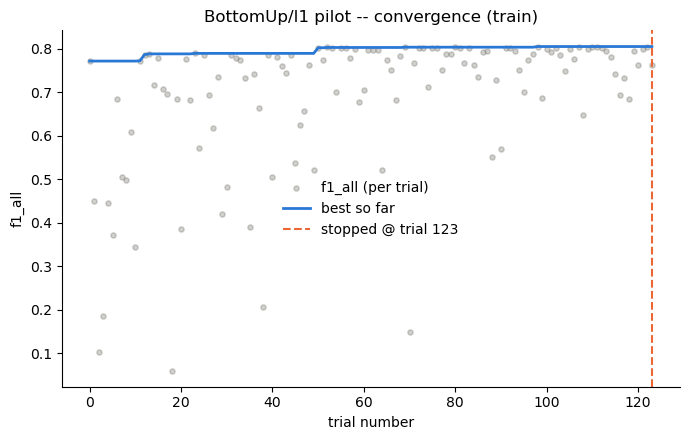

In [11]:
from optuna.trial import TrialState

completed = sorted((t for t in study.trials if t.state == TrialState.COMPLETE), key=lambda t: t.number)
numbers = [t.number for t in completed]
values = [t.value for t in completed]
best_so_far = pd.Series(values).cummax().tolist()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(numbers, values, s=14, alpha=0.4, color="#898781", label=f'f1_{OBJECTIVE} (per trial)')
ax.plot(numbers, best_so_far, color="#2a78d6", linewidth=2, label='best so far')
if stop_info['stopped_early']:
    ax.axvline(stop_info['stopped_at_trial'], color="#eb6834", linestyle='--', linewidth=1.5,
               label=f"stopped @ trial {stop_info['stopped_at_trial']}")
ax.set_xlabel('trial number')
ax.set_ylabel(f'f1_{OBJECTIVE}')
ax.set_title(f'{METHOD}/{COST} pilot -- convergence (train)')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Winning config -- train

In [12]:
best = study.best_trial
best_full_params = osr._best_full_params(best)
print(f"Best trial #{best.number}: {best.params}")
print()
print(f"  train mean_f1_all     = {best.user_attrs['mean_f1_all']:.4f}")
print(f"  train mean_f1_warming = {best.user_attrs['mean_f1_warming']:.4f}")
print(f"  train mean_f1_cooling = {best.user_attrs['mean_f1_cooling']:.4f}")
print(f"  train mean_precision_warming/cooling = "
      f"{best.user_attrs['mean_precision_warming']:.4f} / {best.user_attrs['mean_precision_cooling']:.4f}")
print(f"  train mean_recall_warming/cooling    = "
      f"{best.user_attrs['mean_recall_warming']:.4f} / {best.user_attrs['mean_recall_cooling']:.4f}")

gap_train = best.user_attrs['mean_f1_warming'] - best.user_attrs['mean_f1_cooling']
print(f"\nwarming - cooling F1 gap (train): {gap_train:+.4f}")

Best trial #98: {'method': 'BottomUp', 'cost_BottomUp': 'l1', 'min_size': 5, 'pen_BottomUp_l1': 6.390299794777026}

  train mean_f1_all     = 0.8048
  train mean_f1_warming = 0.7829
  train mean_f1_cooling = 0.8290
  train mean_precision_warming/cooling = 0.8147 / 0.8872
  train mean_recall_warming/cooling    = 0.7809 / 0.7989

warming - cooling F1 gap (train): -0.0461


## Same config, scored on VALIDATION (independent check -- not what the sampler optimized against)

In [13]:
val_df = search.evaluate_validation(best_full_params)
print(f"val_f1_all     = {val_df['f1_all'].mean():.4f}")
print(f"val_f1_warming = {val_df['f1_warming'].mean():.4f}")
print(f"val_f1_cooling = {val_df['f1_cooling'].mean():.4f}")

gap_val = val_df['f1_warming'].mean() - val_df['f1_cooling'].mean()
print(f"\nwarming - cooling F1 gap (validation): {gap_val:+.4f}")

val_df.head()

val_f1_all     = 0.8071
val_f1_warming = 0.7719
val_f1_cooling = 0.8471

warming - cooling F1 gap (validation): -0.0752


,false_positives_all,error,elapsed_s,precision_all,recall_all,f1_all,timing_mae_all,timing_n_matched_all,precision_warming,recall_warming,f1_warming,timing_mae_warming,timing_n_matched_warming,precision_cooling,recall_cooling,f1_cooling,timing_mae_cooling,timing_n_matched_cooling
0,2,None,0.132154,0.916667,1.000000,0.956522,0.106364,22,0.846154,1.000000,0.916667,0.065455,11,1.000000,1.000000,1.000000,0.147273,11
1,2,None,0.138215,0.913043,0.954545,0.933333,0.092381,21,0.833333,0.909091,0.869565,0.068000,10,1.000000,1.000000,1.000000,0.114545,11
2,3,None,0.125015,0.884615,0.884615,0.884615,0.093043,23,0.846154,0.846154,0.846154,0.123636,11,0.923077,0.923077,0.923077,0.065000,12
3,11,None,0.116495,0.666667,0.956522,0.785714,0.154545,22,0.611111,0.916667,0.733333,0.189091,11,0.733333,1.000000,0.846154,0.120000,11
4,10,None,0.119073,0.666667,0.909091,0.769231,0.079000,20,0.529412,0.818182,0.642857,0.113333,9,0.846154,1.000000,0.916667,0.050909,11


## Plots

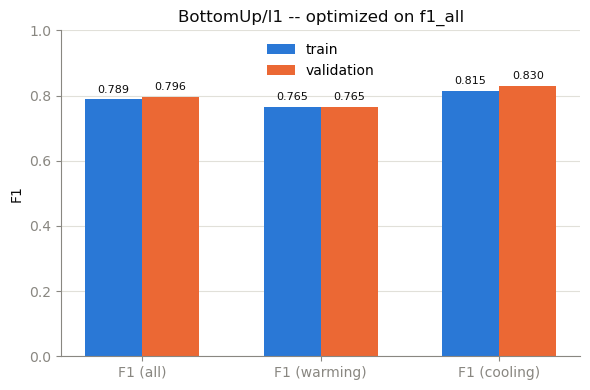

In [7]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

metrics = ["f1_all", "f1_warming", "f1_cooling"]
train_vals = [best.user_attrs['mean_f1_all'], best.user_attrs['mean_f1_warming'], best.user_attrs['mean_f1_cooling']]
val_vals = [val_df['f1_all'].mean(), val_df['f1_warming'].mean(), val_df['f1_cooling'].mean()]

x = np.arange(len(metrics))
width = 0.32

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - width / 2, train_vals, width, label="train", color=BLUE)
ax.bar(x + width / 2, val_vals, width, label="validation", color=ORANGE)

ax.set_xticks(x)
ax.set_xticklabels(["F1 (all)", "F1 (warming)", "F1 (cooling)"], color=INK)
ax.set_ylabel("F1", color=INK)
ax.set_ylim(0, 1)
ax.set_title(f"{METHOD}/{COST} -- optimized on f1_{OBJECTIVE}", color=INK)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color(MUTED)
ax.tick_params(colors=MUTED)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)

for xi, v in zip(x - width / 2, train_vals):
    ax.text(xi, v + 0.02, f"{v:.3f}", ha="center", fontsize=8, color=INK)
for xi, v in zip(x + width / 2, val_vals):
    ax.text(xi, v + 0.02, f"{v:.3f}", ha="center", fontsize=8, color=INK)

plt.tight_layout()
plt.show()

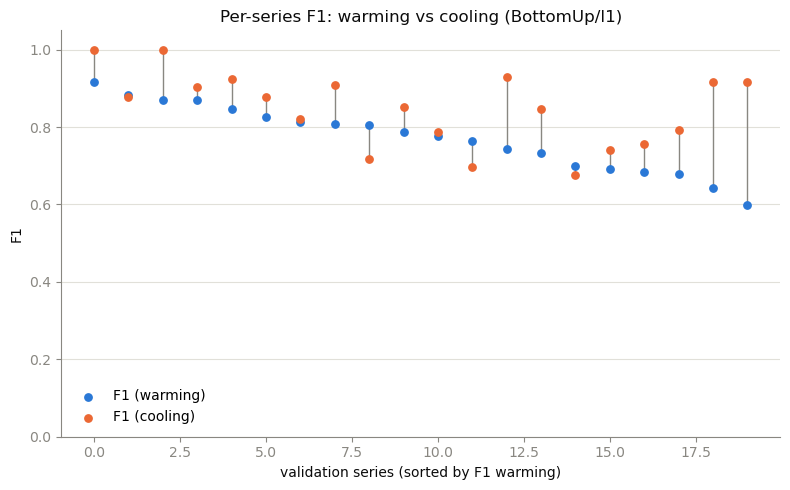

In [7]:
order = np.argsort(-val_df['f1_warming'].values)  # sort by warming F1 for readability
fw = val_df['f1_warming'].values[order]
fc = val_df['f1_cooling'].values[order]
series_idx = np.arange(len(fw))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(series_idx, fw, color=BLUE, s=28, label="F1 (warming)", zorder=3)
ax.scatter(series_idx, fc, color=ORANGE, s=28, label="F1 (cooling)", zorder=3)
for i in series_idx:
    ax.plot([i, i], [fw[i], fc[i]], color=MUTED, linewidth=1, zorder=2)

ax.set_xlabel("validation series (sorted by F1 warming)", color=INK)
ax.set_ylabel("F1", color=INK)
ax.set_ylim(0, 1.05)
ax.set_title(f"Per-series F1: warming vs cooling ({METHOD}/{COST})", color=INK)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color(MUTED)
ax.tick_params(colors=MUTED)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

## Interpretation

_Fill in after running:_
- warming - cooling F1 gap (train): ...
- warming - cooling F1 gap (validation): ...
- Consistent with the supervisor's expectation (little/no gap, since Melcher25's synthetic DO events are more symmetric than real ones) or not?
- If a gap shows up here even in symmetric synthetic data, that's worth noting before attributing any future NGRIP warming/cooling gap purely to real-world asymmetry.
- Did early stopping fire? At what trial, relative to N_TRIALS=150? Does the convergence plot's shape look like a genuine plateau (rule working as intended), or does the best-so-far line still look like it's climbing at the point it stopped (MIN_TRIALS/PATIENCE too aggressive for this search space -- widen them)?

**Action item for the mentoring log** (per supervisor): at some point, explore extending at least one method to explicitly discriminate warming vs cooling -- not needed for this study, noted as a future-work limitation of the current (direction-blind) cost functions.